# Statistiques des retards et contentieux

Ce notebook réunit trois analyses :
- **les flux** (sections 1 à 4) : combien de prêts et de personnes dépassent chaque seuil de retard, année par année, qui sont-elles, et l'effet des rappels avant échéance ;
- **le stock** (sections 5 à 10) : les personnes qui ont aujourd'hui au moins un document en retard de plus de 28 jours, où en est leur dossier dans le circuit (appel, tiers, titre de recette), l'effet et la régularité des appels ;
- **les titres de recette** (section 11) : rapprochement des fichiers Excel de suivi avec Koha.

Circuit de gestion (bloc « adresse alternative » `B_` de la fiche adhérent) :

| Champ | Usage |
|---|---|
| `B_address` | date de l'appel téléphonique |
| `B_address2` | résultat de l'appel (usager joint / message vocal / téléphone inconnu) |
| `B_city` | date de demande de création du tiers |
| `B_zipcode` | numéro de tiers GF |
| `B_state` | numéro du titre de recette ; `0` = pas de titre, montant < 15 € |
| `B_country` | date du titre de recette |
| `contactnote` | documents facturés (code-barres et prix) |

Le nettoyage des champs d'appel des personnes qui ne sont plus en retard se fait avec le script `adm_contentieux_nettoyage_appels.py`.

Règles de méthode :
- **une seule reconstitution des prêts** : l'emprunteur et son profil au moment du prêt viennent de `statdb.stat_issues` (Koha anonymise les prêts rendus) ; l'échéance réelle (prolongations comprises) et la date de retour viennent de Koha, par jointure sur (`itemnumber`, `issuedate`) ;
- tout est calculé à la **date de fraîcheur** des données (dernier mouvement connu dans Koha), pas à la date du jour ;
- un taux n'est publié que si tous les prêts concernés ont eu le temps d'atteindre le seuil ;
- **plancher / plafond** quand une donnée est incertaine (retour douteux, prix manquant, date illisible, retour à date inconnue) ;
- **particuliers** : catégories BIBL, MEDA, MEDB, MEDC, CSVT (sans les collectivités, les comptes génériques ni le personnel) ;
- comparaisons au niveau de l'emprunteur (une personne avec 15 documents ne pèse pas 15 fois), avec intervalles de Wilson à 95 % et tests du χ² ;
- **aucune donnée nominative n'est affichée** : les fichiers de suivi des titres (noms, dates de naissance, garants) sont lus et rapprochés en mémoire. Ne pas ajouter de cellule affichant des lignes individuelles.

In [1]:
import glob
import os
import re
import unicodedata

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from scipy import stats

from kiblib.utils.db import DbConn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
db_conn = DbConn().create_engine()

PARTICULIERS = ['BIBL', 'MEDA', 'MEDB', 'MEDC', 'CSVT']
COLLECTIVITES = ['ECOL', 'CLAS', 'COLS', 'COLD', 'COLI']
DEBUT_HISTORIQUE = '2018-06-01'   # prêts chargés à partir de cette date
ANNEE_DEBUT = 2019                # première année d'échéance analysée
SEUILS = [0, 7, 14, 28, 42, 90, 180]
SEUIL_APPEL = 28                  # entrée dans le circuit (appel téléphonique)
SEUIL_CTX = 42                    # lettre de facture
SEUIL_TITRE_EUR = 15              # seuil de mise en recouvrement
TRANCHES_AGE = [-1, 11, 17, 24, 39, 59, 74, 200]
LIB_AGE = ['0-11', '12-17', '18-24', '25-39', '40-59', '60-74', '75+']
TRANCHES_STOCK = [SEUIL_APPEL, 42, 90, 180, 365, 730, 100000]
LIB_STOCK = ['29-42 j', '43-90 j', '91-180 j', '181-365 j', '1-2 ans', '> 2 ans']
DOSSIER_TITRES = os.path.join("..", "..", "titres")   # fichiers Excel de suivi (hors dépôt : données nominatives)

def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def test_chi2(ct):
    chi2, p, ddl, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return f"χ² = {chi2:.1f}, ddl = {ddl}, p = {p:.2g}, V de Cramér = {v:.3f}"

def mcnemar(b, c):
    return stats.binomtest(b, b + c, 0.5).pvalue

def renseigne(s):
    return s.notna() & (s.astype(str).str.strip() != '')

def lire_date(s):
    s = s.astype(str).str.strip()
    d = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    return d.fillna(pd.to_datetime(s, format='%d/%m/%Y', errors='coerce'))

# Préparation des données

## Date de fraîcheur
La base n'est pas alimentée en continu : on prend le dernier mouvement connu dans Koha (prêt ou retour).

In [3]:
fraicheur = pd.Timestamp(pd.read_sql("""
    SELECT GREATEST((SELECT MAX(issuedate) FROM koha_prod.issues), (SELECT MAX(returndate) FROM koha_prod.old_issues))
""", db_conn).iloc[0, 0]).normalize()
fraicheur

Timestamp('2026-10-14 00:00:00')

## Historique des prêts

- emprunteur et profil au moment du prêt : `statdb.stat_issues` ;
- un prêt est **toujours emprunté** s'il figure dans `koha_prod.issues`, sinon il est **rendu** ; échéance et date de retour viennent de Koha (`issues`, `old_issues`), à défaut de statdb ;
- quand l'exemplaire a été supprimé du catalogue, Koha efface son numéro dans l'historique : on retrouve alors le prêt par sa date et heure exacte de prêt, si elle est unique ;
- il reste quelques prêts rendus à date inconnue : ils sont exclus des taux (on ne sait pas s'ils ont dépassé le seuil), et servent de borne dans la section 7.

**Retour douteux** (plafond) : prêt rendu en retard, dernier prêt de l'exemplaire, exemplaire aujourd'hui non restitué (1) ou perdu (2) : le « retour » peut être la mise en perte plutôt qu'un retour physique. Si l'exemplaire a été reprêté ensuite, le retour était réel.

In [4]:
p = pd.read_sql(f"""
SELECT borrowernumber, itemnumber, issuedate, date_due AS due_s, returndate AS ret_s,
       categorycode, age, sexe, fidelite, branchcode AS site_inscription
FROM statdb.stat_issues WHERE issuedate >= '{DEBUT_HISTORIQUE}'
""", db_conn).drop_duplicates(['itemnumber', 'issuedate'])
cours = pd.read_sql("SELECT itemnumber, issuedate, date_due AS due_k FROM koha_prod.issues", db_conn)
cours['en_cours'] = True
anciens = pd.read_sql(f"""
SELECT itemnumber, issuedate, date_due AS due_o, returndate AS ret_o
FROM koha_prod.old_issues WHERE issuedate >= '{DEBUT_HISTORIQUE}' AND itemnumber IS NOT NULL
""", db_conn).drop_duplicates(['itemnumber', 'issuedate'])
orphelins = pd.read_sql(f"""
SELECT issuedate, date_due AS due_orph, returndate AS ret_orph
FROM koha_prod.old_issues WHERE itemnumber IS NULL AND issuedate >= '{DEBUT_HISTORIQUE}'
""", db_conn)
orphelins = orphelins[~orphelins['issuedate'].duplicated(keep=False)]
exemplaires = pd.read_sql("""
SELECT it.itemnumber, it.itemlost, d.dernier_pret_exemplaire
FROM koha_prod.items it
LEFT JOIN (SELECT itemnumber, MAX(issuedate) AS dernier_pret_exemplaire FROM (
    SELECT itemnumber, issuedate FROM koha_prod.issues
    UNION ALL SELECT itemnumber, issuedate FROM koha_prod.old_issues WHERE itemnumber IS NOT NULL) t
    GROUP BY itemnumber) d ON d.itemnumber = it.itemnumber
""", db_conn)

p = (p.merge(cours.drop_duplicates(['itemnumber', 'issuedate']), on=['itemnumber', 'issuedate'], how='left')
      .merge(anciens, on=['itemnumber', 'issuedate'], how='left')
      .merge(orphelins, on='issuedate', how='left')
      .merge(exemplaires, on='itemnumber', how='left'))
p['en_cours'] = p['en_cours'].fillna(False).astype(bool)
a_completer = ~p['en_cours'] & p['ret_o'].isna()
p.loc[~a_completer, ['due_orph', 'ret_orph']] = None

p['echeance'] = pd.to_datetime(p['due_k'].fillna(p['due_o']).fillna(p['due_orph']).fillna(p['due_s']), errors='coerce').dt.normalize()
p['retour'] = pd.to_datetime(p['ret_o'].fillna(p['ret_orph']).fillna(p['ret_s']), errors='coerce').dt.normalize().where(~p['en_cours'])
p['retour_inconnu'] = ~p['en_cours'] & p['retour'].isna()
p.loc[p['retour'] > fraicheur, 'retour'] = pd.NaT   # retour postérieur à la fraîcheur : non rendu à cette date
p['non_rendu'] = p['retour'].isna() & ~p['retour_inconnu']
p['retard'] = (p['retour'].fillna(fraicheur) - p['echeance']).dt.days
p['retour_douteux'] = (~p['non_rendu'] & ~p['retour_inconnu'] & (p['issuedate'] == p['dernier_pret_exemplaire'])
                       & p['itemlost'].isin([1, 2]) & (p['retard'] > 0))
p['annee_echeance'] = p['echeance'].dt.year
p['mois_echeance'] = p['echeance'].dt.to_period('M')
p['tranche_age'] = pd.cut(pd.to_numeric(p['age'], errors='coerce'), TRANCHES_AGE, labels=LIB_AGE)

print(len(p), "prêts depuis", DEBUT_HISTORIQUE, "; toujours empruntés :", int(p['en_cours'].sum()),
      "; date de retour retrouvée par la date-heure de prêt :", int(p['ret_orph'].notna().sum()),
      "; rendus à date inconnue :", int(p['retour_inconnu'].sum()))

# prêts des particuliers, échus, à retour connu : base des taux
prets = p[p['categorycode'].isin(PARTICULIERS) & ~p['retour_inconnu'] & (p['echeance'] <= fraicheur)
          & (p['annee_echeance'] >= ANNEE_DEBUT)].copy()
print(len(prets), "prêts de particuliers échus depuis", ANNEE_DEBUT, ",", prets['borrowernumber'].nunique(), "emprunteurs ;",
      int(prets['retour_douteux'].sum()), "retours douteux")

2691038 prêts depuis 2018-06-01 ; toujours empruntés : 40443 ; date de retour retrouvée par la date-heure de prêt : 345657 ; rendus à date inconnue : 19616
2291398 prêts de particuliers échus depuis 2019 , 33783 emprunteurs ; 139 retours douteux


## Adhérents et bloc `B_`

In [5]:
adh = pd.read_sql("""
SELECT borrowernumber, cardnumber, surname, firstname, dateofbirth, categorycode, branchcode, dateexpiry,
       phone, mobile, email,
       B_address, B_address2, B_city, B_state, B_zipcode, B_country, contactnote
FROM koha_prod.borrowers
""", db_conn)

for champ, nom in [('B_address', 'date_appel'), ('B_city', 'date_tiers'), ('B_country', 'date_titre')]:
    adh[nom] = lire_date(adh[champ])
    adh[nom + '_illisible'] = renseigne(adh[champ]) & adh[nom].isna()

adh['resultat_appel'] = adh['B_address2'].where(adh['B_address2'].isin(['usager joint', 'message vocal', 'téléphone inconnu']))
etat = adh['B_state'].astype(str).str.strip()
adh['etat_titre'] = np.select([etat == '0', etat.str.fullmatch(r'\d{6,9}')], ['0 (< 15 €)', 'numéro'], default=None)
adh['tel'] = renseigne(adh['phone']) | renseigne(adh['mobile'])
adh['courriel'] = renseigne(adh['email'])

# montant facturé lu dans contactnote : "(7.90)" ou "- 7.90"
def montant(note):
    if not isinstance(note, str):
        return np.nan
    m = re.findall(r'(?:\(|-\s*)(\d+[.,]\d{1,2})', note)
    return sum(float(x.replace(',', '.')) for x in m) if m else np.nan
adh['montant_note'] = adh['contactnote'].map(montant)

susp = pd.read_sql("""
SELECT borrowernumber, MIN(created) AS date_suspension
FROM koha_prod.borrower_debarments WHERE type = 'OVERDUES' GROUP BY borrowernumber
""", db_conn)
adh = adh.merge(susp, on='borrowernumber', how='left')
adh['dernier_pret'] = adh['borrowernumber'].map(p.groupby('borrowernumber')['issuedate'].max())
print(len(adh), "adhérents ; dates illisibles :", {c: int(adh[c].sum()) for c in adh.columns if c.endswith('_illisible')})

35598 adhérents ; dates illisibles : {'date_appel_illisible': 29, 'date_tiers_illisible': 29, 'date_titre_illisible': 0}


# 1. Taux de retard par année d'échéance

Pour chaque année d'échéance et chaque seuil : part des prêts, puis part des emprunteurs ayant **au moins un** prêt, rendus après le seuil ou toujours pas rendus. Pour l'année en cours, un seuil n'est calculé que sur les prêts assez anciens pour l'avoir atteint.

Plancher : retours Koha tels quels ; plafond : retours douteux comptés comme non rendus.

In [6]:
def depasse(df, s, plafond=False):
    x = df['retard'] > s
    if plafond:
        x = x | (df['retour_douteux'] & ((fraicheur - df['echeance']).dt.days > s))
    return x

def observable(df, s):
    return df[df['echeance'] + pd.Timedelta(days=s) <= fraicheur]

def par_emprunteur(df, s, plafond=False, periode='annee_echeance'):
    return depasse(df, s, plafond).groupby([df[periode], df['borrowernumber']]).any()

annees_completes = [a for a in range(ANNEE_DEBUT, fraicheur.year + 1)
                    if pd.Timestamp(f'{a}-12-31') + pd.Timedelta(days=max(SEUILS)) <= fraicheur]
print("années complètes à tous les seuils :", annees_completes)

lignes = []
for s in SEUILS:
    o = observable(prets, s)
    bas, haut = par_emprunteur(o, s), par_emprunteur(o, s, plafond=True)
    n = bas.groupby(level=0).size()
    ic_bas, _ = wilson(bas.groupby(level=0).sum(), n)
    _, ic_haut = wilson(haut.groupby(level=0).sum(), n)
    lignes.append(pd.DataFrame({
        'seuil': f'> {s} j',
        'prêts': o.groupby('annee_echeance').size(),
        'prêts plancher %': 100 * depasse(o, s).groupby(o['annee_echeance']).mean(),
        'prêts plafond %': 100 * depasse(o, s, True).groupby(o['annee_echeance']).mean(),
        'emprunteurs': n,
        'emprunteurs plancher %': 100 * bas.groupby(level=0).mean(),
        'emprunteurs plafond %': 100 * haut.groupby(level=0).mean(),
        'IC95 bas %': 100 * ic_bas, 'IC95 haut %': 100 * ic_haut}))
taux = pd.concat(lignes).rename_axis('année').reset_index()
ordre_seuils = [f'> {s} j' for s in SEUILS]
print("Écart plafond - plancher, en points (max) : prêts",
      round((taux['prêts plafond %'] - taux['prêts plancher %']).max(), 2),
      "; emprunteurs", round((taux['emprunteurs plafond %'] - taux['emprunteurs plancher %']).max(), 2))
print("Part des prêts (plancher) :")
taux.pivot(index='année', columns='seuil', values='prêts plancher %')[ordre_seuils].round(2)

années complètes à tous les seuils : [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Écart plafond - plancher, en points (max) : prêts 0.03 ; emprunteurs 0.46
Part des prêts (plancher) :


seuil,> 0 j,> 7 j,> 14 j,> 28 j,> 42 j,> 90 j,> 180 j
année,,,,,,,
2019,35.59,23.54,16.72,5.84,2.71,0.83,0.55
2020,45.50,35.92,30.19,20.11,15.40,6.03,1.27
2021,29.91,18.92,13.41,5.20,2.41,0.66,0.42
2022,25.77,14.86,10.14,4.40,2.40,0.75,0.45
2023,25.46,14.41,9.64,4.06,2.03,0.62,0.40
2024,24.54,13.98,9.30,3.75,1.79,0.55,0.34
2025,24.99,14.12,9.27,3.60,1.46,0.52,0.34
2026,22.80,12.35,7.41,3.03,1.40,0.48,0.36


In [7]:
print("Part des emprunteurs ayant au moins un prêt au-delà du seuil (plancher) :")
taux.pivot(index='année', columns='seuil', values='emprunteurs plancher %')[ordre_seuils].round(1)

Part des emprunteurs ayant au moins un prêt au-delà du seuil (plancher) :


seuil,> 0 j,> 7 j,> 14 j,> 28 j,> 42 j,> 90 j,> 180 j
année,,,,,,,
2019,81.9,71.5,62.2,34.7,20.0,7.9,5.6
2020,87.6,82.1,78.2,67.6,60.4,34.8,10.0
2021,81.5,69.5,59.7,33.0,19.3,7.3,5.1
2022,76.6,60.8,49.5,27.1,17.1,7.2,4.7
2023,75.8,60.0,48.2,25.9,15.7,5.9,4.3
2024,75.6,59.7,48.0,25.9,15.3,5.7,4.2
2025,75.6,58.6,47.3,24.6,12.6,5.4,4.0
2026,69.8,51.6,36.9,19.2,10.8,4.1,2.1


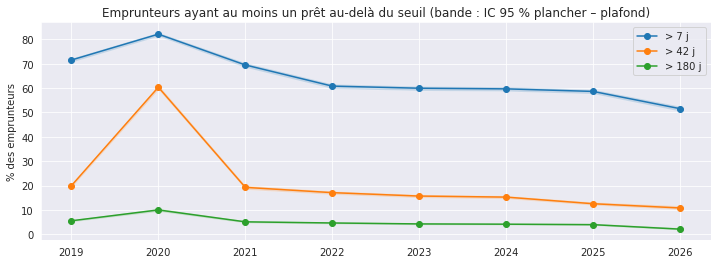

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
for s in [7, 42, 180]:
    t = taux[taux['seuil'] == f'> {s} j']
    ax.plot(t['année'], t['emprunteurs plancher %'], marker='o', label=f'> {s} j')
    ax.fill_between(t['année'], t['IC95 bas %'], t['IC95 haut %'], alpha=0.2)
ax.set_ylabel("% des emprunteurs")
ax.set_title("Emprunteurs ayant au moins un prêt au-delà du seuil (bande : IC 95 % plancher – plafond)")
ax.legend()
plt.show()

Comparaison des deux dernières années complètes. Au niveau prêt : χ² (indicatif, les prêts d'une même personne ne sont pas indépendants). Au niveau emprunteur : test de McNemar exact sur les personnes présentes les deux années.

In [9]:
a1, a2 = annees_completes[-2], annees_completes[-1]
for s in SEUILS:
    o = observable(prets[prets['annee_echeance'].isin([a1, a2])], s)
    chi2, p_chi2, _, _ = stats.chi2_contingency(pd.crosstab(o['annee_echeance'], depasse(o, s)))
    e = par_emprunteur(o, s).unstack(level=0).dropna()
    b, c = int((e[a1] & ~e[a2]).sum()), int((~e[a1] & e[a2]).sum())
    print(f"> {s:>3} j : prêts χ² p = {p_chi2:.1g} ; emprunteurs présents les deux années ({len(e)}) : "
          f"sortis {b}, entrés {c}, McNemar p = {mcnemar(b, c):.1g}")

>   0 j : prêts χ² p = 4e-05 ; emprunteurs présents les deux années (6966) : sortis 685, entrés 875, McNemar p = 2e-06
>   7 j : prêts χ² p = 0.1 ; emprunteurs présents les deux années (6966) : sortis 949, entrés 1097, McNemar p = 0.001
>  14 j : prêts χ² p = 0.6 ; emprunteurs présents les deux années (6966) : sortis 971, entrés 1151, McNemar p = 0.0001
>  28 j : prêts χ² p = 0.002 ; emprunteurs présents les deux années (6966) : sortis 739, entrés 888, McNemar p = 0.0002
>  42 j : prêts χ² p = 2e-24 ; emprunteurs présents les deux années (6966) : sortis 498, entrés 519, McNemar p = 0.5
>  90 j : prêts χ² p = 0.1 ; emprunteurs présents les deux années (6966) : sortis 126, entrés 260, McNemar p = 8e-12
> 180 j : prêts χ² p = 0.8 ; emprunteurs présents les deux années (6966) : sortis 51, entrés 178, McNemar p = 1e-17


# 2. Récupération des documents en contentieux

Parmi les prêts ayant dépassé 42 jours de retard, part finalement rendue dans les 90, 180 et 365 jours suivant l'échéance (années d'échéance complètes pour chaque horizon). Haut : retours Koha tels quels ; bas : retours douteux comptés comme non rendus.

In [10]:
ctx = prets[depasse(prets, SEUIL_CTX)].copy()
recup = {}
for horizon in [90, 180, 365]:
    rendu = ~ctx['non_rendu'] & (ctx['retard'] <= horizon)
    complet = pd.to_datetime(ctx['annee_echeance'].astype(str) + '-12-31') + pd.Timedelta(days=horizon) <= fraicheur
    g = ctx.assign(rendu=rendu, rendu_bas=rendu & ~ctx['retour_douteux'])[complet].groupby('annee_echeance')
    recup[f'rendu ≤ {horizon} j (haut) %'] = 100 * g['rendu'].mean()
    recup[f'rendu ≤ {horizon} j (bas) %'] = 100 * g['rendu_bas'].mean()
recup = pd.DataFrame(recup).round(1)
recup.insert(0, 'prêts > 42 j', ctx.groupby('annee_echeance').size())
recup

,prêts > 42 j,rendu ≤ 90 j (haut) %,rendu ≤ 90 j (bas) %,rendu ≤ 180 j (haut) %,rendu ≤ 180 j (bas) %,rendu ≤ 365 j (haut) %,rendu ≤ 365 j (bas) %
annee_echeance,,,,,,,
2019,8414,69.5,69.5,79.5,79.5,83.8,83.8
2020,34413,60.8,60.8,91.8,91.8,96.6,96.6
2021,6762,72.7,72.7,82.8,82.8,88.5,88.5
2022,7140,68.7,68.7,81.3,81.3,85.6,85.6
2023,6246,69.4,69.3,80.5,80.4,85.5,85.4
2024,5775,69.5,69.4,81.0,80.8,84.6,84.5
2025,4494,64.6,64.6,76.9,76.8,NaN,NaN


In [11]:
print("Prêts > 42 j toujours non rendus, selon le statut actuel de l'exemplaire (itemlost) :")
pd.crosstab(ctx.loc[ctx['non_rendu'], 'annee_echeance'], ctx.loc[ctx['non_rendu'], 'itemlost'].fillna(-1).astype(int))

Prêts > 42 j toujours non rendus, selon le statut actuel de l'exemplaire (itemlost) :


itemlost,0,1,2
annee_echeance,,,
2019,5,853,0
2020,26,714,0
2021,13,390,0
2022,18,693,0
2023,15,706,1
2024,10,706,0
2025,0,767,0
2026,10,738,0


# 3. Profil des emprunteurs en contentieux (> 42 jours)

Dernière année complète. Profil enregistré au moment du premier prêt échu de l'année. Pour chaque dimension : taux par groupe (plancher / plafond, IC 95 %) et test du χ² d'indépendance (plancher, groupes d'au moins 30 personnes).

La catégorie de carte est aussi liée au volume d'emprunt (plus on emprunte, plus on a d'occasions d'être en retard) : le taux au niveau prêt, en dernière colonne, sépare « exposition » et « comportement ».

In [12]:
a = annees_completes[-1]
d = prets[prets['annee_echeance'] == a].sort_values('echeance')
emp = d.groupby('borrowernumber').agg(categorycode=('categorycode', 'first'), tranche_age=('tranche_age', 'first'),
                                      sexe=('sexe', 'first'), fidelite=('fidelite', 'first'), site=('site_inscription', 'first'))
emp['ctx'] = depasse(d, SEUIL_CTX).groupby(d['borrowernumber']).any()
emp['ctx_plafond'] = depasse(d, SEUIL_CTX, True).groupby(d['borrowernumber']).any()
emp['anciennete'] = pd.cut(pd.to_numeric(emp['fidelite'], errors='coerce'), [-1, 0, 2, 5, 10, 100],
                           labels=['< 1 an', '1-2 ans', '3-5 ans', '6-10 ans', '> 10 ans'])

def tableau_taux(df, groupe):
    t = df.groupby(groupe).agg(emprunteurs=('ctx', 'size'), ctx=('ctx', 'sum'), ctx_plafond=('ctx_plafond', 'sum'))
    t['plancher %'] = 100 * t['ctx'] / t['emprunteurs']
    t['plafond %'] = 100 * t['ctx_plafond'] / t['emprunteurs']
    t['IC95 bas %'] = 100 * wilson(t['ctx'], t['emprunteurs'])[0]
    t['IC95 haut %'] = 100 * wilson(t['ctx_plafond'], t['emprunteurs'])[1]
    return t.drop(columns=['ctx', 'ctx_plafond']).round(1)

for dim in ['categorycode', 'tranche_age', 'sexe', 'anciennete', 'site']:
    ct = pd.crosstab(emp[dim], emp['ctx'])
    print(f"\n=== {dim} ({a}) — {test_chi2(ct[ct.sum(axis=1) >= 30])}")
    t = tableau_taux(emp, dim)
    if dim == 'categorycode':
        t['prêts > 42 j %'] = (100 * depasse(d, SEUIL_CTX).groupby(d['categorycode']).mean()).round(2)
    display(t)


=== categorycode (2025) — χ² = 23.7, ddl = 4, p = 9e-05, V de Cramér = 0.046


,emprunteurs,plancher %,plafond %,IC95 bas %,IC95 haut %,prêts > 42 j %
categorycode,,,,,,
BIBL,10354,12.7,12.8,12.0,13.4,1.66
CSVT,149,17.4,17.4,12.2,24.3,1.13
MEDA,154,3.9,4.5,1.8,9.1,0.38
MEDB,209,6.2,7.2,3.7,11.5,0.40
MEDC,277,15.5,16.6,11.7,21.4,1.13



=== tranche_age (2025) — χ² = 137.3, ddl = 6, p = 3.6e-27, V de Cramér = 0.111


,emprunteurs,plancher %,plafond %,IC95 bas %,IC95 haut %
tranche_age,,,,,
0-11,3599,15.8,15.9,14.7,17.2
12-17,1589,15.0,15.1,13.4,16.9
18-24,922,11.6,11.8,9.7,14.1
25-39,1726,12.7,12.8,11.3,14.5
40-59,2250,10.1,10.4,9.0,11.7
60-74,815,3.7,3.9,2.6,5.5
75+,242,2.5,2.5,1.1,5.3



=== sexe (2025) — χ² = 2.4, ddl = 2, p = 0.3, V de Cramér = 0.015


,emprunteurs,plancher %,plafond %,IC95 bas %,IC95 haut %
sexe,,,,,
,31,16.1,16.1,7.1,32.6
F,6780,12.2,12.3,11.4,13.1
M,4328,13.1,13.2,12.1,14.3
O,4,25.0,25.0,4.6,69.9



=== anciennete (2025) — χ² = 9.9, ddl = 4, p = 0.041, V de Cramér = 0.030


,emprunteurs,plancher %,plafond %,IC95 bas %,IC95 haut %
anciennete,,,,,
< 1 an,3481,13.6,13.8,12.5,14.9
1-2 ans,2972,12.3,12.4,11.1,13.7
3-5 ans,1888,12.6,12.8,11.1,14.4
6-10 ans,1586,12.5,12.6,10.9,14.3
> 10 ans,1212,10.2,10.4,8.6,12.2



=== site (2025) — χ² = 2.2, ddl = 1, p = 0.14, V de Cramér = 0.014


,emprunteurs,plancher %,plafond %,IC95 bas %,IC95 haut %
site,,,,,
BUS,507,14.8,14.8,12.0,18.1
MED,10636,12.4,12.6,11.8,13.3


# 4. Rappels avant échéance et retards courts

Depuis avril 2026, Koha envoie beaucoup plus de rappels avant échéance (`PREDUE`, `PREDUEDGST`). Mois d'échéance par mois d'échéance : part des emprunteurs ayant au moins un prêt rendu en retard (> 0, 7 et 14 jours), comparée au volume de rappels et au même mois de 2025.

Coïncidence dans le temps n'est pas preuve. Pour mieux isoler l'effet, la **différence de différences** compare, par tranche d'âge, l'écart 2026 − 2025 sur mai-septembre (rappels massifs) au même écart sur janvier-mars (période de référence) ; IC 95 % par approximation normale. L'arrêt des suspensions automatiques (fin mars 2026) aurait plutôt dû faire monter les retards.

In [13]:
rappels = pd.read_sql("""
SELECT YEAR(time_queued) AS annee, MONTH(time_queued) AS mois, COUNT(*) AS rappels
FROM koha_prod.message_queue
WHERE letter_code IN ('PREDUE', 'PREDUEDGST') AND time_queued >= '2025-01-01'
GROUP BY annee, mois
""", db_conn)
rappels.index = [pd.Period(f"{a}-{m:02d}", 'M') for a, m in zip(rappels['annee'], rappels['mois'])]

r = prets[(prets['echeance'] >= '2025-01-01') & (prets['echeance'] + pd.Timedelta(days=14) <= fraicheur)].copy()
emp_mois = pd.DataFrame({f'> {s} j %': par_emprunteur(r, s, periode='mois_echeance') for s in [0, 7, 14]})
mensuel = 100 * emp_mois.groupby(level=0).mean()
mensuel.insert(0, 'emprunteurs', emp_mois.groupby(level=0).size())
mensuel['rappels avant échéance'] = rappels['rappels']
mensuel.fillna(0).round(1).T

mois_echeance,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
emprunteurs,3711.0,3097.0,3900.0,3627.0,3733.0,3427.0,2983.0,2682.0,2657.0,3391.0,3833.0,3516.0,3607.0,3283.0,3555.0,3558.0,3686.0,3373.0,3062.0,2609.0,2921.0
> 0 j %,48.7,40.5,46.7,44.3,46.4,48.2,41.5,46.4,44.0,45.2,47.5,45.3,48.5,42.9,43.8,45.1,39.6,40.5,35.5,42.2,40.9
> 7 j %,29.2,24.7,29.3,27.2,29.0,28.5,25.2,28.4,26.6,27.7,28.9,28.9,29.1,26.0,25.7,28.0,22.8,23.7,21.0,25.3,22.5
> 14 j %,20.0,17.3,21.7,19.3,21.5,19.6,18.2,20.1,17.3,19.0,20.2,20.8,19.3,18.7,18.7,17.1,13.9,13.4,13.4,15.5,11.6
rappels avant échéance,260.0,334.0,268.0,332.0,248.0,226.0,297.0,270.0,210.0,282.0,278.0,207.0,257.0,234.0,222.0,4037.0,3680.0,3522.0,2775.0,2793.0,3035.0


In [14]:
m = mensuel.copy()
m['année'], m['mois'] = m.index.year, m.index.month
cols = ['> 0 j %', '> 7 j %', '> 14 j %']
comparaison = m.pivot_table(index='mois', columns='année', values=cols)
for col in cols:
    comparaison[(col, 'écart 2026 - 2025')] = comparaison[(col, 2026)] - comparaison[(col, 2025)]
comparaison.dropna()[[(c, a) for c in cols for a in [2025, 2026, 'écart 2026 - 2025']]].round(1)

> 0 j %                         > 7 j %                         > 14 j %                        
année    2025  2026 écart 2026 - 2025    2025  2026 écart 2026 - 2025     2025  2026 écart 2026 - 2025
mois                                                                                                  
1        48.7  48.5              -0.1    29.2  29.1              -0.1     20.0  19.3              -0.7
2        40.5  42.9               2.4    24.7  26.0               1.3     17.3  18.7               1.3
3        46.7  43.8              -2.9    29.3  25.7              -3.6     21.7  18.7              -3.0
4        44.3  45.1               0.7    27.2  28.0               0.8     19.3  17.1              -2.2
5        46.4  39.6              -6.8    29.0  22.8              -6.2     21.5  13.9              -7.7
6        48.2  40.5              -7.6    28.5  23.7              -4.8     19.6  13.4              -6.2
7        41.5  35.5              -6.0    25.2  21.0              -4.2     18.2  13.4              -4.7
8        46.4  42.2              -4.3    28.4  25.3              -3.2     20.1  15.5              -4.6
9        44.0  40.9              -3.2    26.6  22.5              -4.2     17.3  11.6              -5.7

In [15]:
r['periode'] = np.select([r['echeance'].dt.month.between(1, 3), r['echeance'].dt.month.between(5, 9)], ['janv-mars', 'mai-sept'], default='')
r = r[r['periode'] != ''].sort_values('echeance')
r['cle'] = r['annee_echeance'].astype(str) + ' ' + r['periode']
e = pd.DataFrame({'tranche_age': r.groupby(['cle', 'borrowernumber'])['tranche_age'].first()})
for s in [0, 7, 14]:
    e[f'> {s} j'] = par_emprunteur(r, s, periode='cle')
e = e.reset_index()
e['annee'], e['periode'] = e['cle'].str[:4].astype(int), e['cle'].str[5:]

lignes = []
for tranche, g in list(e.groupby('tranche_age')) + [('Toutes', e)]:
    for s in [0, 7, 14]:
        x = g.groupby(['periode', 'annee'])[f'> {s} j'].agg(['mean', 'size'])
        ecart = {}
        for per in ['janv-mars', 'mai-sept']:
            p25, n25 = x.loc[(per, 2025)]
            p26, n26 = x.loc[(per, 2026)]
            ecart[per] = (100 * (p26 - p25), 100 * np.sqrt(p25 * (1 - p25) / n25 + p26 * (1 - p26) / n26))
        did = ecart['mai-sept'][0] - ecart['janv-mars'][0]
        se = np.hypot(ecart['mai-sept'][1], ecart['janv-mars'][1])
        lignes.append({'tranche': tranche, 'seuil': f'> {s} j',
                       'écart mai-sept': ecart['mai-sept'][0], 'écart janv-mars': ecart['janv-mars'][0],
                       'diff. de diff.': did, 'IC95 bas': did - 1.96 * se, 'IC95 haut': did + 1.96 * se,
                       'emprunteurs mai-sept 2026': int(x.loc[('mai-sept', 2026), 'size'])})
did_age = pd.DataFrame(lignes)
did_age.pivot(index='tranche', columns='seuil', values='diff. de diff.')[['> 0 j', '> 7 j', '> 14 j']].round(1)

seuil,> 0 j,> 7 j,> 14 j
tranche,,,
0-11,-3.9,-4.5,-6.7
12-17,-12.1,-16.5,-15.1
18-24,-4.4,-9.5,-14.4
25-39,-13.4,-12.8,-15.8
40-59,-6.8,-5.7,-9.3
60-74,-8.8,-7.7,-7.5
75+,-13.3,-2.6,-0.7
Toutes,-7.9,-8.2,-10.1


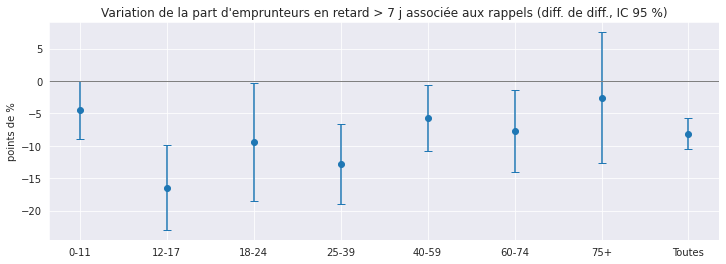

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
d7 = did_age[did_age['seuil'] == '> 7 j']
ax.errorbar(d7['tranche'].astype(str), d7['diff. de diff.'],
            yerr=[d7['diff. de diff.'] - d7['IC95 bas'], d7['IC95 haut'] - d7['diff. de diff.']], fmt='o', capsize=4)
ax.axhline(0, color='grey', lw=1)
ax.set_ylabel('points de %')
ax.set_title("Variation de la part d'emprunteurs en retard > 7 j associée aux rappels (diff. de diff., IC 95 %)")
plt.show()

# 5. Le stock actuel (plus de 28 jours de retard)

Photographie à la date de fraîcheur, à partir des prêts en cours dans Koha (toutes catégories). Valeur : plancher = prix de remplacement Koha, prix manquant compté 0 ; plafond = prix manquant remplacé par la médiane du type de document.

In [17]:
actuels = pd.read_sql("""
SELECT i.borrowernumber, i.itemnumber, i.issuedate, i.date_due,
       it.replacementprice, it.itemlost, it.itype, it.biblionumber
FROM koha_prod.issues i
LEFT JOIN koha_prod.items it ON it.itemnumber = i.itemnumber
""", db_conn)
actuels['echeance'] = pd.to_datetime(actuels['date_due'], errors='coerce').dt.normalize()
actuels['retard'] = (fraicheur - actuels['echeance']).dt.days
actuels['prix'] = actuels['replacementprice'].where(actuels['replacementprice'] > 0)
prix_type = pd.read_sql("SELECT itype, replacementprice FROM koha_prod.items WHERE replacementprice > 0",
                        db_conn).groupby('itype')['replacementprice'].median()
actuels['prix_haut'] = actuels['prix'].fillna(actuels['itype'].map(prix_type)).fillna(prix_type.median())
actuels['prix_bas'] = actuels['prix'].fillna(0)
resa = pd.read_sql("SELECT DISTINCT biblionumber FROM koha_prod.reserves", db_conn)
actuels['titre_reserve'] = actuels['biblionumber'].isin(resa['biblionumber'])

en_retard = actuels[actuels['retard'] > SEUIL_APPEL]
stock = en_retard.groupby('borrowernumber').agg(
    docs=('itemnumber', 'size'), plus_ancienne_echeance=('echeance', 'min'), retard_max=('retard', 'max'),
    valeur_bas=('prix_bas', 'sum'), valeur_haut=('prix_haut', 'sum')).reset_index()
stock = stock.merge(adh, on='borrowernumber', how='left')
stock['tranche'] = pd.cut(stock['retard_max'], TRANCHES_STOCK, labels=LIB_STOCK)
stock['type'] = np.select([stock['categorycode'].isin(PARTICULIERS), stock['categorycode'].isin(COLLECTIVITES)],
                          ['particulier', 'collectivité'], default='autre (CGEN, personnel…)')
print(len(actuels), "prêts en cours ;", len(en_retard), "en retard de plus de", SEUIL_APPEL, "jours, dont",
      int(en_retard['prix'].isna().sum()), "sans prix de remplacement ;", len(stock), "personnes")

def synthese(df, groupe):
    t = df.groupby(groupe).agg(personnes=('borrowernumber', 'size'), docs=('docs', 'sum'),
                               valeur_bas=('valeur_bas', 'sum'), valeur_haut=('valeur_haut', 'sum'))
    t.loc['Total'] = t.sum()
    t['% personnes'] = 100 * t['personnes'] / t.loc['Total', 'personnes']
    t['% docs'] = 100 * t['docs'] / t.loc['Total', 'docs']
    return t.round(1)

display(synthese(stock, 'type'))
synthese(stock, 'tranche')

41531 prêts en cours ; 9319 en retard de plus de 28 jours, dont 2179 sans prix de remplacement ; 2887 personnes


,personnes,docs,valeur_bas,valeur_haut,% personnes,% docs
type,,,,,,
"autre (CGEN, personnel…)",34.0,111.0,1010.9,1333.1,1.2,1.2
collectivité,193.0,2381.0,20593.7,28427.7,6.7,25.5
particulier,2660.0,6827.0,67866.7,90231.6,92.1,73.3
Total,2887.0,9319.0,89471.3,119992.4,100.0,100.0


,personnes,docs,valeur_bas,valeur_haut,% personnes,% docs
tranche,,,,,,
29-42 j,60.0,206.0,1923.9,2703.2,2.1,2.2
43-90 j,75.0,214.0,1980.8,2811.8,2.6,2.3
91-180 j,136.0,335.0,3115.5,4418.0,4.7,3.6
181-365 j,205.0,438.0,4991.0,6705.0,7.1,4.7
1-2 ans,382.0,861.0,7756.4,10514.4,13.2,9.2
> 2 ans,2029.0,7265.0,69703.8,92840.0,70.3,78.0
Total,2887.0,9319.0,89471.3,119992.4,100.0,100.0


  1 % des personnes (29) détiennent 20.0 % des documents, 18.0 % de la valeur (plancher)
 10 % des personnes (289) détiennent 45.7 % des documents, 45.7 % de la valeur (plancher)
 20 % des personnes (577) détiennent 61.1 % des documents, 61.0 % de la valeur (plancher)


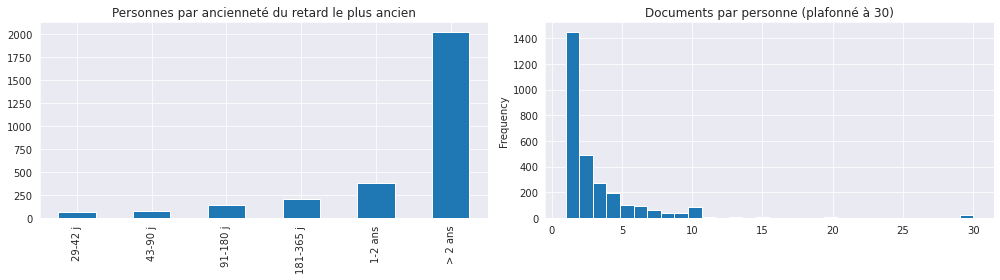

In [18]:
s = stock.sort_values('docs', ascending=False)
for q in [0.01, 0.10, 0.20]:
    n = int(round(q * len(s)))
    print(f"{int(q*100):>3} % des personnes ({n}) détiennent {100*s['docs'].head(n).sum()/s['docs'].sum():.1f} % des documents, "
          f"{100*s['valeur_bas'].head(n).sum()/s['valeur_bas'].sum():.1f} % de la valeur (plancher)")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
stock['tranche'].value_counts().reindex(LIB_STOCK).plot.bar(ax=axes[0], title='Personnes par ancienneté du retard le plus ancien')
stock['docs'].clip(upper=30).plot.hist(bins=30, ax=axes[1], title='Documents par personne (plafonné à 30)')
plt.tight_layout()
plt.show()

# 6. Où en est chaque dossier dans le circuit ?

Une étape n'est retenue que si sa date est postérieure à la plus ancienne échéance en retard : une information plus ancienne concerne un dossier antérieur (le bloc n'a qu'un emplacement par étape), la personne est alors considérée comme non traitée.

Étapes, de la plus avancée à la moins avancée : 1. titre émis ; 2. clos sans titre, montant < 15 € (`B_state = 0`) ; 3. titre daté sans numéro ; 4. tiers demandé ; 5. appelé (selon le résultat) ; 6. non traité, avec ou sans téléphone.

Bornes : une date illisible est comptée comme rattachée au dossier actuel pour le plancher des « non traités », et comme non rattachée pour le plafond.

In [19]:
def etape(df, illisible_rattache):
    def lie(nom):
        return (df[nom] >= df['plus_ancienne_echeance']) | (df[nom + '_illisible'] & illisible_rattache)
    titre_lie, tiers_lie, appel_lie = lie('date_titre'), lie('date_tiers'), lie('date_appel')
    return pd.Series(np.select(
        [titre_lie & (df['etat_titre'] == 'numéro'),
         titre_lie & (df['etat_titre'] == '0 (< 15 €)'),
         titre_lie,
         tiers_lie,
         appel_lie & (df['resultat_appel'] == 'usager joint'),
         appel_lie & (df['resultat_appel'] == 'message vocal'),
         appel_lie & (df['resultat_appel'] == 'téléphone inconnu'),
         appel_lie,
         df['tel']],
        ['1 titre émis', '2 clos < 15 €', '3 titre daté sans numéro', '4 tiers demandé',
         '5a appelé : usager joint', '5b appelé : message vocal', '5c appelé : téléphone inconnu', '5d appelé : résultat non noté',
         '6a non traité, téléphone connu'],
        default='6b non traité, sans téléphone'), index=df.index)

stock['etape'] = etape(stock, illisible_rattache=True)
stock['etape_haut'] = etape(stock, illisible_rattache=False)
stock['bloc_dossier_anterieur'] = (renseigne(stock['B_address']) | renseigne(stock['B_country'])) & stock['etape'].str.startswith('6')
part = stock[stock['type'] == 'particulier'].copy()
print("Particuliers non traités : plancher", int(part['etape'].str.startswith('6').sum()),
      "/ plafond", int(part['etape_haut'].str.startswith('6').sum()),
      "; dont bloc B_ rempli pour un dossier antérieur :", int(part['bloc_dossier_anterieur'].sum()))
pd.crosstab(part['etape'], part['tranche'], margins=True, margins_name='Total')

Particuliers non traités : plancher 372 / plafond 372 ; dont bloc B_ rempli pour un dossier antérieur : 125


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
etape,,,,,,,
1 titre émis,0,0,0,0,73,979,1052
2 clos < 15 €,0,0,0,0,85,523,608
3 titre daté sans numéro,0,0,0,0,0,104,104
4 tiers demandé,0,0,0,0,9,10,19
5a appelé : usager joint,0,6,21,42,32,14,115
5b appelé : message vocal,0,29,71,114,105,6,325
5c appelé : téléphone inconnu,0,0,5,30,22,7,64
5d appelé : résultat non noté,0,0,0,0,1,0,1
"6a non traité, téléphone connu",57,33,27,12,34,160,323


In [20]:
part.groupby('etape').agg(personnes=('borrowernumber', 'size'), docs=('docs', 'sum'),
                          valeur_bas=('valeur_bas', 'sum'), valeur_haut=('valeur_haut', 'sum'),
                          retard_median_j=('retard_max', 'median')).round(0)

,personnes,docs,valeur_bas,valeur_haut,retard_median_j
etape,,,,,
1 titre émis,1052,3536,37693.0,47793.0,1619.0
2 clos < 15 €,608,741,5141.0,7475.0,1596.0
3 titre daté sans numéro,104,381,4427.0,5421.0,3110.0
4 tiers demandé,19,26,260.0,293.0,1134.0
5a appelé : usager joint,115,233,2119.0,2944.0,291.0
5b appelé : message vocal,325,709,5674.0,9266.0,278.0
5c appelé : téléphone inconnu,64,185,2728.0,3219.0,324.0
5d appelé : résultat non noté,1,1,11.0,11.0,498.0
"6a non traité, téléphone connu",323,877,8226.0,11804.0,698.0


## Lettres de facture et suspensions automatiques
Les règles de relance Koha envoient un premier rappel à 7 jours, un deuxième à 14 jours et une facture à 42 jours. La suspension automatique (`OVERDUES`) a été désactivée fin mars 2026. Or le rapport 208 (titres de recettes à créer) part des suspensions : les dossiers ouverts depuis ne peuvent pas y apparaître.

In [21]:
suspensions_mois = pd.read_sql("""
SELECT YEAR(created) AS annee, MONTH(created) AS mois, COUNT(*) AS suspensions
FROM koha_prod.borrower_debarments WHERE type = 'OVERDUES' AND created >= '2025-01-01'
GROUP BY annee, mois
""", db_conn)
lettres_mois = pd.read_sql("""
SELECT YEAR(time_queued) AS annee, MONTH(time_queued) AS mois, COUNT(*) AS factures_42j
FROM koha_prod.message_queue WHERE letter_code = 'FACTURE' AND time_queued >= '2025-01-01'
GROUP BY annee, mois
""", db_conn)
nouveaux = part[part['plus_ancienne_echeance'] + pd.Timedelta(days=42) >= pd.Timestamp('2026-03-30')]
print("Particuliers du stock dont le retard a atteint 42 j après le 30/03/2026 :", len(nouveaux),
      "; suspendus :", int(nouveaux['date_suspension'].notna().sum()))
(lettres_mois.merge(suspensions_mois, on=['annee', 'mois'], how='outer').fillna(0).astype(int)
 .sort_values(['annee', 'mois']).set_index(['annee', 'mois']).T)

Particuliers du stock dont le retard a atteint 42 j après le 30/03/2026 : 326 ; suspendus : 1


annee        2025                                                       2026                                            
mois           1    2    3    4    5    6    7    8    9   10   11   12   1    2    3    4    5    6    7    8    9   10
factures_42j  244  158  198  193  195  158  208  163  130  92  119  154  154  135  115  120  194  162  145  145  122  54
suspensions    23   34   28   29   42   23   40   50   33  18   17   22   22   45   33    0    0    0    0    0    0   0

## Délais du circuit
Sur les dates lisibles et cohérentes (appel après l'échéance, titre après l'appel). L'échéance de référence est la plus ancienne échéance des prêts en cours (approximation).

In [22]:
dl = adh.merge(stock[['borrowernumber', 'plus_ancienne_echeance']], on='borrowernumber', how='left')
delais = pd.DataFrame({
    'échéance → appel': (dl['date_appel'] - dl['plus_ancienne_echeance']).dt.days,
    'appel → titre': (dl['date_titre'] - dl['date_appel']).dt.days,
    'demande tiers → titre': (dl['date_titre'] - dl['date_tiers']).dt.days,
})
delais = delais.where(delais >= 0)
display(delais.describe(percentiles=[.1, .25, .5, .75, .9]).round(0))
annee_appel, annee_titre = dl['date_appel'].dt.year, dl['date_titre'].dt.year
pd.DataFrame({
    'appels': dl.groupby(annee_appel).size(),
    'délai médian appel → titre (j)': delais['appel → titre'].groupby(annee_appel).median(),
    'titres datés': dl.groupby(annee_titre).size(),
    'dont 0 (< 15 €)': dl[dl['etat_titre'] == '0 (< 15 €)'].groupby(annee_titre).size(),
}).fillna(0).astype(int).rename(index=int)

,échéance → appel,appel → titre,demande tiers → titre
count,2090.0,1592.0,1852.0
mean,232.0,262.0,13.0
std,270.0,211.0,66.0
min,0.0,0.0,0.0
10%,34.0,34.0,0.0
25%,43.0,110.0,0.0
50%,81.0,200.0,0.0
75%,433.0,415.0,3.0
90%,615.0,538.0,32.0
max,2729.0,1462.0,1128.0


,appels,délai médian appel → titre (j),titres datés,dont 0 (< 15 €)
2018,0,0,4,0
2019,0,0,106,0
2020,60,204,0,0
2021,690,153,598,215
2022,164,167,229,99
2023,376,415,295,121
2024,210,505,180,84
2025,305,106,210,83
2026,1790,62,384,160


# 7. L'appel téléphonique fait-il revenir les documents ?

Pour chaque personne appelée depuis 2023 : prêts en retard au jour de l'appel, puis part des personnes ayant rendu **au moins un** de ces documents, et **tous** ces documents, dans les 7, 14, 42, 90 et 180 jours qui suivent l'appel. Un délai n'est calculé que pour les appels assez anciens pour l'avoir entièrement observé.

Bornes : les prêts rendus à date inconnue sont comptés comme rendus après le délai (plancher) ou dans le délai (plafond).

Limites : le bloc ne garde que le **dernier** appel ; il n'y a pas de groupe témoin tiré au hasard. « Téléphone inconnu » (personne non jointe) sert de point de comparaison, mais ces personnes diffèrent sans doute des autres : la comparaison est descriptive, pas causale.

In [23]:
DELAIS_APPEL = [7, 14, 42, 90, 180]
appeles = adh[(adh['date_appel'] >= '2023-01-01') & (adh['date_appel'] <= fraicheur - pd.Timedelta(days=min(DELAIS_APPEL)))
              & adh['resultat_appel'].notna()][['borrowernumber', 'date_appel', 'resultat_appel']]
h = p[['borrowernumber', 'itemnumber', 'issuedate', 'echeance', 'retour', 'en_cours', 'retour_inconnu']].merge(appeles, on='borrowernumber')
# en retard au jour de l'appel : échéance passée, et toujours emprunté ou rendu après l'appel
# (un prêt rendu à date inconnue est conservé : on ne sait pas s'il était déjà rendu)
h = h[(h['issuedate'] < h['date_appel']) & (h['echeance'] < h['date_appel'])
      & (h['en_cours'] | h['retour_inconnu'] | (h['retour'] > h['date_appel']))].copy()
agg = {}
for j in DELAIS_APPEL:
    rendu = h['retour'].notna() & (h['retour'] <= h['date_appel'] + pd.Timedelta(days=j))
    h[f'bas_{j}'], h[f'haut_{j}'] = rendu, rendu | h['retour_inconnu']
    for b in ['bas', 'haut']:
        agg[f'un_{b}_{j}'] = (f'{b}_{j}', 'any')
        agg[f'tous_{b}_{j}'] = (f'{b}_{j}', 'all')
pers = h.groupby(['borrowernumber', 'resultat_appel', 'date_appel']).agg(docs=('itemnumber', 'size'), **agg).reset_index()
print(len(appeles), "personnes appelées ;", len(pers), "avec au moins un prêt en retard au jour de l'appel ;",
      len(h), "prêts, dont", int(h['retour_inconnu'].sum()), "rendus à date inconnue")

lignes = []
for j in DELAIS_APPEL:
    obs = pers[pers['date_appel'] + pd.Timedelta(days=j) <= fraicheur]
    for groupe, g in list(obs.groupby('resultat_appel')) + [('Total', obs)]:
        for quoi in ['un', 'tous']:
            lignes.append({'délai': f'{j} j', 'résultat appel': groupe,
                           'indicateur': 'au moins 1 doc rendu' if quoi == 'un' else 'tous les docs rendus',
                           'personnes': len(g), 'plancher %': 100 * g[f'{quoi}_bas_{j}'].mean(),
                           'plafond %': 100 * g[f'{quoi}_haut_{j}'].mean()})
effet_appel = pd.DataFrame(lignes).round(1)
ordre_delais = [f'{j} j' for j in DELAIS_APPEL]
effet_appel[effet_appel['indicateur'] == 'au moins 1 doc rendu'].pivot(
    index='résultat appel', columns='délai', values=['personnes', 'plancher %', 'plafond %']).reindex(columns=ordre_delais, level=1)

2665 personnes appelées ; 2405 avec au moins un prêt en retard au jour de l'appel ; 8524 prêts, dont 899 rendus à date inconnue


personnes                                 plancher %                         plafond %                        
délai                   7 j    14 j    42 j    90 j   180 j        7 j  14 j  42 j  90 j 180 j       7 j  14 j  42 j  90 j 180 j
résultat appel                                                                                                                  
Total                2405.0  2405.0  2345.0  2210.0  1557.0       22.5  31.9  42.6  46.3  50.9      26.9  35.9  45.7  49.1  53.3
message vocal        1348.0  1348.0  1302.0  1214.0   827.0       21.3  30.2  40.9  45.3  49.7      26.0  34.5  44.5  48.7  52.6
téléphone inconnu     291.0   291.0   288.0   281.0   228.0        6.9  15.8  24.7  27.4  30.3      12.4  20.3  27.4  30.2  33.8
usager joint          766.0   766.0   755.0   715.0   502.0       30.4  40.9  52.3  55.4  62.4      33.9  44.3  54.7  57.3  63.3

In [24]:
print("Tous les documents rendus :")
effet_appel[effet_appel['indicateur'] == 'tous les docs rendus'].pivot(
    index='résultat appel', columns='délai', values=['plancher %', 'plafond %']).reindex(columns=ordre_delais, level=1)

Tous les documents rendus :


plancher %                         plafond %                        
délai                    7 j  14 j  42 j  90 j 180 j       7 j  14 j  42 j  90 j 180 j
résultat appel                                                                        
Total                   16.8  24.4  33.6  36.3  38.2      19.5  27.5  37.5  40.9  42.8
message vocal           15.7  23.1  32.4  35.7  37.8      18.7  26.7  36.7  40.9  43.7
téléphone inconnu        3.4  10.3  16.3  16.4  17.1       4.8  12.7  19.8  19.9  19.7
usager joint            23.9  31.9  42.3  45.0  48.2      26.4  34.6  45.7  49.0  52.0

χ² : la part de personnes ayant rendu au moins un document diffère-t-elle selon le résultat de l'appel ?
  7 j (2405 personnes) — plancher : χ² = 69.5, ddl = 2, p = 8e-16, V de Cramér = 0.170 ; plafond : χ² = 51.1, ddl = 2, p = 8.2e-12, V de Cramér = 0.146
 14 j (2405 personnes) — plancher : χ² = 64.9, ddl = 2, p = 8.2e-15, V de Cramér = 0.164 ; plafond : χ² = 55.3, ddl = 2, p = 9.9e-13, V de Cramér = 0.152
 42 j (2345 personnes) — plancher : χ² = 68.7, ddl = 2, p = 1.2e-15, V de Cramér = 0.171 ; plafond : χ² = 64.1, ddl = 2, p = 1.2e-14, V de Cramér = 0.165
 90 j (2210 personnes) — plancher : χ² = 64.6, ddl = 2, p = 9.5e-15, V de Cramér = 0.171 ; plafond : χ² = 59.5, ddl = 2, p = 1.2e-13, V de Cramér = 0.164
180 j (1557 personnes) — plancher : χ² = 65.7, ddl = 2, p = 5.5e-15, V de Cramér = 0.205 ; plafond : χ² = 55.5, ddl = 2, p = 9.1e-13, V de Cramér = 0.189


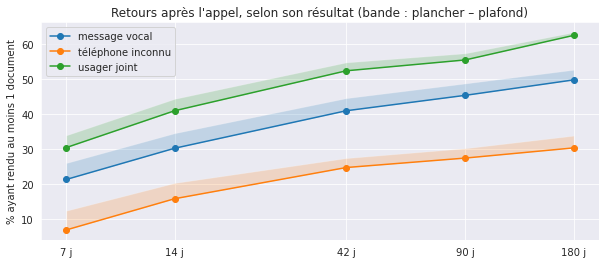

In [25]:
print("χ² : la part de personnes ayant rendu au moins un document diffère-t-elle selon le résultat de l'appel ?")
for j in DELAIS_APPEL:
    obs = pers[pers['date_appel'] + pd.Timedelta(days=j) <= fraicheur]
    res = [f"{nom} : {test_chi2(pd.crosstab(obs['resultat_appel'], obs[f'un_{b}_{j}']))}" for b, nom in [('bas', 'plancher'), ('haut', 'plafond')]]
    print(f"{j:>3} j ({len(obs)} personnes) — " + " ; ".join(res))

fig, ax = plt.subplots(figsize=(10, 4))
t = effet_appel[(effet_appel['indicateur'] == 'au moins 1 doc rendu') & (effet_appel['résultat appel'] != 'Total')]
for groupe, g in t.groupby('résultat appel'):
    x = [int(v.split()[0]) for v in g['délai']]
    ax.plot(x, g['plancher %'], marker='o', label=groupe)
    ax.fill_between(x, g['plancher %'], g['plafond %'], alpha=0.2)
ax.set_xscale('log')
ax.set_xticks(DELAIS_APPEL)
ax.set_xticklabels(ordre_delais)
ax.set_ylabel('% ayant rendu au moins 1 document')
ax.set_title("Retours après l'appel, selon son résultat (bande : plancher – plafond)")
ax.legend()
plt.show()

# 8. Régularité des appels

Mois par mois, nombre d'appels notés dans le bloc `B_` comparé au nombre de particuliers qui franchissent 28 jours de retard, et part de ceux qui sont appelés ensuite.

Limites : le bloc ne garde que le dernier appel (volumes anciens **sous-estimés**) ; « appelée ensuite » compte aussi un appel noté plus tard pour un autre dossier (couverture **surestimée**) ; les derniers mois sont incomplets.

In [26]:
DEBUT_REGULARITE = pd.Timestamp('2025-01-01')
jours_fr = ['lundi', 'mardi', 'mercredi', 'jeudi', 'vendredi', 'samedi', 'dimanche']
ap = adh[(adh['date_appel'] >= DEBUT_REGULARITE) & (adh['date_appel'] <= fraicheur)][['borrowernumber', 'date_appel', 'B_address']].copy()
ap['format_date'] = np.where(ap['B_address'].astype(str).str.strip().str.fullmatch(r'\d{2}/\d{2}/\d{4}'), 'JJ/MM/AAAA', 'AAAA-MM-JJ')

jours_appel = ap.groupby('date_appel').size()
print(len(ap), "appels notés depuis", DEBUT_REGULARITE.date(), "sur", len(jours_appel), "jours différents")
print("appels par jour d'appel :", jours_appel.describe(percentiles=[.25, .5, .75, .9]).round(1).to_dict())
print("intervalle entre deux jours d'appels (j) :", jours_appel.index.to_series().diff().dt.days.dropna().describe(percentiles=[.25, .5, .75, .9]).round(0).to_dict())

b28 = p[p['categorycode'].isin(PARTICULIERS)].copy()
b28['jour_29'] = b28['echeance'] + pd.Timedelta(days=SEUIL_APPEL + 1)
b28 = b28[(b28['jour_29'] >= DEBUT_REGULARITE) & (b28['jour_29'] <= fraicheur)
          & (b28['retour'].isna() | (b28['retour'] >= b28['jour_29']))]
b28['mois'] = b28['jour_29'].dt.to_period('M')
entrees_28 = (b28.sort_values('jour_29').drop_duplicates(['borrowernumber', 'mois'])
              .merge(ap[['borrowernumber', 'date_appel']], on='borrowernumber', how='left'))
entrees_28['appelee_ensuite'] = entrees_28['date_appel'] >= entrees_28['jour_29'] - pd.Timedelta(days=1)

regularite = pd.DataFrame({
    'franchissent 28 j': entrees_28.groupby('mois').size(),
    'appels notés': ap.groupby(ap['date_appel'].dt.to_period('M')).size(),
    "jours d'appels": ap.groupby(ap['date_appel'].dt.to_period('M'))['date_appel'].nunique(),
    'appelées ensuite %': 100 * entrees_28.groupby('mois')['appelee_ensuite'].mean(),
}).fillna(0)
regularite.round(0).astype(int).T

2095 appels notés depuis 2025-01-01 sur 133 jours différents
appels par jour d'appel : {'count': 133.0, 'mean': 15.8, 'std': 24.1, 'min': 1.0, '25%': 2.0, '50%': 7.0, '75%': 20.0, '90%': 37.6, 'max': 158.0}
intervalle entre deux jours d'appels (j) : {'count': 132.0, 'mean': 5.0, 'std': 6.0, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, '90%': 11.0, 'max': 31.0}


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
franchissent 28 j,447,273,290,366,303,356,296,253,226,203,266,322,334,267,321,297,264,215,234,197,151,79
appels notés,2,1,6,7,14,39,32,37,39,10,18,100,216,253,218,345,275,191,176,23,87,6
jours d'appels,2,1,3,3,4,5,7,11,8,4,4,10,12,8,10,11,7,7,8,3,4,1
appelées ensuite %,30,32,37,32,35,33,33,30,42,33,36,52,72,80,68,65,55,56,60,37,23,0


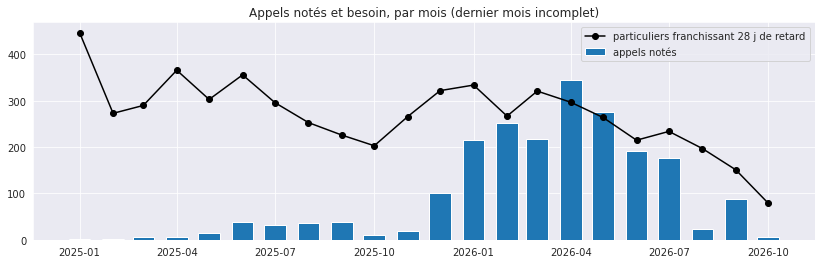

In [27]:
fig, ax = plt.subplots(figsize=(14, 4))
x = regularite.index.to_timestamp()
ax.bar(x, regularite['appels notés'], width=20, label='appels notés')
ax.plot(x, regularite['franchissent 28 j'], color='black', marker='o', label='particuliers franchissant 28 j de retard')
ax.set_title('Appels notés et besoin, par mois (dernier mois incomplet)')
ax.legend()
plt.show()

## Retard au jour de l'appel
Plus ancienne échéance encore en retard le jour de l'appel. Le circuit prévoit l'appel à partir de 28 jours.

In [28]:
ha = p.merge(ap[['borrowernumber', 'date_appel']], on='borrowernumber')
ha = ha[(ha['issuedate'] < ha['date_appel']) & (ha['echeance'] < ha['date_appel'])
        & (ha['retour'].isna() | (ha['retour'] > ha['date_appel']))]
ret_appel = ha.groupby(['borrowernumber', 'date_appel'])['echeance'].min().reset_index()
ret_appel['retard'] = (ret_appel['date_appel'] - ret_appel['echeance']).dt.days
g = ret_appel.groupby(ret_appel['date_appel'].dt.to_period('Q'))['retard']
t = g.describe(percentiles=[.25, .5, .75])[['count', '25%', '50%', '75%']]
t['29-42 j %'] = g.apply(lambda s: 100 * s.between(29, 42).mean())
t['> 90 j %'] = g.apply(lambda s: 100 * (s > 90).mean())
t.round(0).T

date_appel,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
count,8.0,55.0,99.0,121.0,598.0,689.0,265.0,6.0
25%,60.0,35.0,30.0,36.0,33.0,38.0,33.0,52.0
50%,66.0,40.0,33.0,38.0,35.0,49.0,40.0,56.0
75%,73.0,45.0,36.0,43.0,43.0,522.0,46.0,57.0
29-42 j %,0.0,67.0,84.0,69.0,74.0,38.0,52.0,0.0
> 90 j %,12.0,2.0,3.0,11.0,18.0,45.0,5.0,0.0


## Dates d'appel suspectes
Beaucoup d'appels sont datés du 20 du mois, y compris un lundi ou un samedi : probablement une date de saisie groupée ou conventionnelle plutôt que le jour réel de l'appel. À vérifier avec les personnes qui saisissent.

In [29]:
print("jours de la semaine :", ap['date_appel'].dt.dayofweek.map(dict(enumerate(jours_fr))).value_counts().reindex(jours_fr).fillna(0).astype(int).to_dict())
print("jours du mois les plus fréquents :", ap['date_appel'].dt.day.value_counts().head(6).to_dict())
le_20 = ap[ap['date_appel'].dt.day == 20]
pd.crosstab(le_20['date_appel'].dt.date.astype(str) + ' (' + le_20['date_appel'].dt.dayofweek.map(dict(enumerate(jours_fr))) + ')',
            le_20['format_date'], margins=True, margins_name='Total')

jours de la semaine : {'lundi': 134, 'mardi': 314, 'mercredi': 672, 'jeudi': 440, 'vendredi': 316, 'samedi': 219, 'dimanche': 0}
jours du mois les plus fréquents : {20: 455, 18: 167, 4: 151, 16: 109, 26: 95, 15: 88}


format_date,AAAA-MM-JJ,JJ/MM/AAAA,Total
date_appel,,,
2025-09-20 (samedi),2,0,2
2025-12-20 (samedi),1,0,1
2026-01-20 (mardi),2,18,20
2026-02-20 (vendredi),0,2,2
2026-03-20 (vendredi),14,49,63
2026-04-20 (lundi),0,134,134
2026-05-20 (mercredi),0,158,158
2026-06-20 (samedi),0,75,75
Total,19,436,455


# 9. Évolution du stock (24 derniers mois)

Particuliers, à partir de l'historique des prêts :
- **stock** en fin de mois : prêts dont le retard dépasse 28 jours et non rendus à cette date, et personnes concernées ;
- **entrée** : prêt dont le retard atteint 29 jours dans le mois ; **sortie** : retour dans le mois d'un prêt qui avait plus de 28 jours de retard. Les prêts jamais rendus ne sortent pas.

Le dernier mois est incomplet. Les prêts empruntés avant le début de l'historique et toujours en cours ne sont pas comptés (voir le contrôle).

In [30]:
mois = pd.period_range((fraicheur - pd.DateOffset(months=24)).to_period('M'), fraicheur.to_period('M'), freq='M')
lignes = []
for m in mois:
    d = min(m.to_timestamp(how='end').normalize(), fraicheur)
    s = prets[(prets['echeance'] + pd.Timedelta(days=SEUIL_APPEL) < d) & (prets['retour'].isna() | (prets['retour'] > d))]
    lignes.append({'mois': m, 'prêts en stock': len(s), 'personnes en stock': s['borrowernumber'].nunique()})
evolution = pd.DataFrame(lignes).set_index('mois')
passes_28 = prets[prets['retard'] > SEUIL_APPEL]
evolution['entrées'] = passes_28.groupby((passes_28['echeance'] + pd.Timedelta(days=SEUIL_APPEL + 1)).dt.to_period('M')).size()
evolution['sorties'] = passes_28.groupby(passes_28['retour'].dt.to_period('M')).size()
evolution = evolution.fillna(0).astype(int)
print("contrôle : prêts en cours empruntés avant", DEBUT_HISTORIQUE, ":",
      int((actuels['issuedate'] < DEBUT_HISTORIQUE).sum()))
evolution.T

contrôle : prêts en cours empruntés avant 2018-06-01 : 992


mois,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
prêts en stock,4886,4929,5144,5253,5129,5191,5189,5261,5392,5528,5602,5496,5464,5520,5612,5673,5630,5765,5802,5995,6005,5943,6092,5838,5911
personnes en stock,1845,1862,1946,1983,1988,1983,2017,2040,2104,2127,2145,2111,2095,2124,2167,2192,2190,2252,2265,2340,2354,2348,2377,2322,2326
entrées,858,773,1006,1463,654,908,1072,955,1111,905,886,912,737,843,1051,1076,864,979,921,730,628,743,697,527,321
sorties,810,730,791,1354,778,846,1074,883,980,769,812,1018,769,787,959,1015,907,844,884,537,618,805,548,781,248


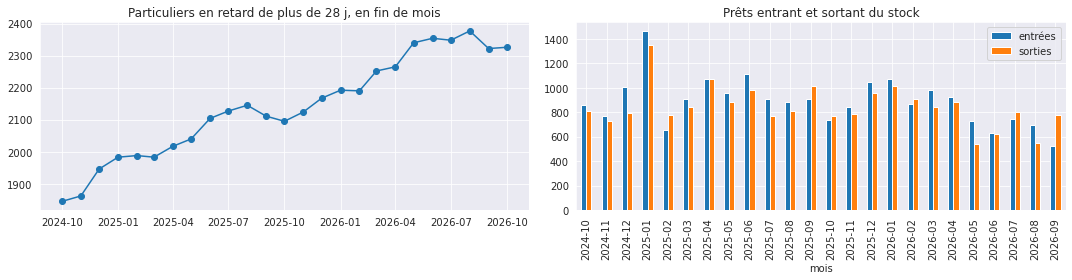

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
x = evolution.index.to_timestamp()
axes[0].plot(x, evolution['personnes en stock'], marker='o')
axes[0].set_title('Particuliers en retard de plus de 28 j, en fin de mois')
evolution[['entrées', 'sorties']].iloc[:-1].plot.bar(ax=axes[1], title='Prêts entrant et sortant du stock')
axes[1].set_xticklabels([str(m) for m in evolution.index[:-1]], rotation=90)
plt.tight_layout()
plt.show()

# 10. Les personnes et les documents du stock (particuliers)

Les personnes qui ont **emprunté à nouveau depuis le début de leur retard** sont revenues à la médiathèque : elles peuvent être interceptées au guichet.

In [32]:
part['carte expirée'] = pd.to_datetime(part['dateexpiry'], errors='coerce') < fraicheur
part['a emprunté depuis'] = part['dernier_pret'] > part['plus_ancienne_echeance']
profil = 100 * part.groupby('tranche')[['tel', 'courriel', 'carte expirée', 'a emprunté depuis']].mean().rename(columns={'tel': 'téléphone'})
profil.insert(0, 'personnes', part.groupby('tranche').size())
display(profil.round(1))
age = (fraicheur - pd.to_datetime(part['dateofbirth'], errors='coerce')).dt.days / 365.25
pd.crosstab(pd.cut(age, TRANCHES_AGE, labels=LIB_AGE), part['tranche'], margins=True, margins_name='Total')

,personnes,téléphone,courriel,carte expirée,a emprunté depuis
tranche,,,,,
29-42 j,58,98.3,93.1,8.6,1.7
43-90 j,70,97.1,92.9,10.0,0.0
91-180 j,125,96.8,92.8,16.8,2.4
181-365 j,198,87.4,90.9,37.9,2.5
1-2 ans,362,94.8,84.5,97.2,4.1
> 2 ans,1847,84.6,62.6,99.2,4.7


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
dateofbirth,,,,,,,
0-11,17,22,57,88,143,181,508
12-17,13,11,19,41,74,540,698
18-24,5,8,11,25,45,370,464
25-39,6,11,18,25,58,417,535
40-59,13,16,18,15,35,281,378
60-74,3,2,1,4,5,45,60
75+,1,0,1,0,2,13,17
Total,58,70,125,198,362,1847,2660


In [33]:
docs = en_retard.merge(part[['borrowernumber', 'tranche']], on='borrowernumber')
print("statut de l'exemplaire (itemlost : 0 = disponible en théorie, 1 = non restitué, 2 = perdu) :")
display(pd.crosstab(docs['itemlost'].fillna(-1).astype(int), docs['tranche'], margins=True, margins_name='Total'))
print("documents dont le titre fait l'objet d'une réservation en attente :", int(docs['titre_reserve'].sum()))
docs.groupby('itype').agg(docs=('itemnumber', 'size'), valeur_bas=('prix_bas', 'sum'),
                          prix_median=('prix', 'median')).sort_values('docs', ascending=False).head(15).round(1)

statut de l'exemplaire (itemlost : 0 = disponible en théorie, 1 = non restitué, 2 = perdu) :


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
itemlost,,,,,,,
0,200,53,1,0,4,86,344
1,2,145,298,426,808,4803,6482
2,0,0,0,0,0,1,1
Total,202,198,299,426,812,4890,6827


documents dont le titre fait l'objet d'une réservation en attente : 352


,docs,valeur_bas,prix_median
itype,,,
PRETLIV,6269,61413.9,10.9
PRETPER,246,127.0,18.0
PRETDVD,188,4369.0,35.8
PRETSON,80,1234.7,17.0
PRETLS,31,503.0,20.0
PRETPAR,12,213.8,20.7
PRETCAR,1,5.3,5.3


# 11. Titres de recette

Rapprochement des fichiers Excel de suivi des titres de recette avec Koha : combien de titres sont émis chaque année et pour quel montant, à quelle année de contentieux ils correspondent, et quelle part des personnes en contentieux fait l'objet d'un dossier.

Définitions (fichiers de suivi) :
- **dossier** : une ligne des fichiers ;
- **titre émis** : `N° titre` renseigné et différent de 0. Un même titre peut couvrir plusieurs lignes, presque toujours une **fratrie** (plusieurs enfants, même garant, même numéro de tiers) : les **dossiers** comptent les personnes et les dettes, les **titres distincts** les actes envoyés au Trésor public, les **montants** sont additionnés ligne par ligne ;
- suite donnée (colonne Commentaires) : titre **réglé** (au Trésor public), **annulé** (l'usager a remboursé à la médiathèque ; parfois « documents rendus »), « ok » ou sans commentaire. Un titre annulé a bien été émis ;
- **pas de titre émis** : `N° titre` vide ou 0 ; motif dans la colonne Commentaires.

Clés de rapprochement, de la plus fiable à la moins fiable : la référence RAP (« FACTURE n° RAP jj/mm/aaaa/X… », date de la lettre de facture et numéro de carte) ; nom + prénom + date de naissance ; numéro de titre (`B_state`) ; numéro de tiers (`B_zipcode`).

In [34]:
def norm(s):
    if pd.isna(s):
        return ''
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    return re.sub(r'[^A-Z]', '', s)

def numero(s):
    if pd.isna(s):
        return ''
    s = str(int(s)) if isinstance(s, float) else str(s)
    return re.sub(r'\D', '', s).lstrip('0')

def date_rap(s):
    m = re.search(r'(\d{1,2})[/.-](\d{1,2})[/.-](\d{4})', str(s)) or re.search(r'RAP\s*(\d{2})(\d{2})(\d{4})', str(s))
    if not m:
        return pd.NaT
    try:
        return pd.Timestamp(int(m.group(3)), int(m.group(2)), int(m.group(1)))
    except ValueError:
        return pd.NaT

lignes = []
for f in sorted(glob.glob(os.path.join(DOSSIER_TITRES, '*.xlsx'))):
    for feuille in pd.ExcelFile(f).sheet_names:
        x = pd.read_excel(f, sheet_name=feuille)
        x.columns = [str(c).strip() for c in x.columns]
        if 'Nom' not in x or 'N° titre' not in x:
            continue   # feuille qui n'est pas un suivi de titres
        x = x.loc[:, ~x.columns.duplicated()].dropna(subset=['Nom'])
        col_date = next((c for c in ['Date', 'Date emission du titre'] if c in x), None)
        lignes.append(pd.DataFrame({
            'fichier': os.path.basename(f), 'feuille': feuille,
            'nom': x['Nom'].map(norm), 'prenom': x['Prénom'].map(norm),
            'naissance': pd.to_datetime(x['Date naissance'], errors='coerce').dt.date,
            'tiers': x['N° tiers'].map(numero), 'titre': x['N° titre'].map(numero),
            'montant': pd.to_numeric(x['Montant'], errors='coerce'),
            'date_emission': pd.to_datetime(x[col_date], errors='coerce') if col_date else pd.NaT,
            'rap': x['Ref du RAP'].astype(str),
            'commentaire': x['Commentaires'].astype(str) if 'Commentaires' in x else '',
        }))
suivi = pd.concat(lignes, ignore_index=True)
suivi['numerote'] = suivi['titre'] != ''
com = suivi['commentaire'].str.strip().str.lower().replace('nan', '')
suivi['suite_titre'] = np.select(
    [~suivi['numerote'], com.str.contains('annul') & com.str.contains('rendu'), com.str.contains('annul'),
     com.str.contains('r[ée]gl|pay[ée]'), com == 'ok', com == ''],
    ['', 'annulé (documents rendus)', 'annulé (remboursé à la médiathèque)', 'réglé', 'ok', 'sans commentaire'],
    default='autre commentaire')
suivi['motif_sans_titre'] = np.select(
    [suivi['numerote'], com.str.contains(r'15\s*€|inf[ée]rieur|<'), com.str.contains('garant|usager|coordonn|infos'), com == ''],
    ['', 'somme < 15 €', 'informations manquantes (garant, usager)', 'sans motif'], default='autre motif')
suivi['date_rap'] = suivi['rap'].map(date_rap)
suivi['carte_rap'] = suivi['rap'].str.extract(r'(X\d{5,})', expand=False)
# année du titre : date d'émission, sinon préfixe AAAA du numéro, sinon année de la feuille
prefixe = pd.to_numeric(suivi['titre'].str[:4].where(suivi['titre'].str.len() == 8), errors='coerce')
suivi['annee_titre'] = (suivi['date_emission'].dt.year.fillna(prefixe)
                        .fillna(suivi['feuille'].str.extract(r'(20\d\d)')[0].astype(float)))
ordre_suite = ['réglé', 'annulé (remboursé à la médiathèque)', 'annulé (documents rendus)', 'ok', 'sans commentaire', 'autre commentaire']
regle_ou_annule = ordre_suite[:3]

print(len(suivi), "dossiers ;", int(suivi['numerote'].sum()), "avec numéro de titre ;", suivi.loc[suivi['numerote'], 'titre'].nunique(), "titres distincts")
suivi.groupby(['fichier', 'feuille']).size().to_frame('dossiers')

2356 dossiers ; 1477 avec numéro de titre ; 1391 titres distincts


dossiers
fichier                                       feuille               
Retards 2019_2020_2021.xlsx                   retards 2019       377
                                              retards 2020       362
                                              retards 2021        56
Suivi des titres de recette émis en 2024.xlsx 2024               213
Suivi des titres de recette émis en 2025.xlsx 2025               232
Suivi des titres de recette émis en 2026.xlsx 2026               354
Suivi des titres de recette.xlsx              2021 - 2022        407
                                              2023               355

## Titres par année d'émission
Pour les dossiers sans titre, l'année est celle de la feuille (pas de date d'émission).

In [35]:
em = suivi[suivi['numerote']]
sans = suivi[~suivi['numerote']]
par_emission = pd.DataFrame({
    'dossiers': suivi.groupby('annee_titre').size(),
    'dossiers avec titre': em.groupby('annee_titre').size(),
    'titres émis (distincts)': em.groupby('annee_titre')['titre'].nunique(),
    'montant émis (€)': em.groupby('annee_titre')['montant'].sum(),
    'dossiers sans titre': sans.groupby('annee_titre').size(),
    'montant sans titre (€)': sans.groupby('annee_titre')['montant'].sum(),
}).fillna(0)
par_emission.index = par_emission.index.astype(int)
par_emission.loc['Total'] = par_emission.sum()
display(par_emission.round(0).astype(int))

g = (em.assign(personne=em['nom'] + '|' + em['prenom'] + '|' + em['naissance'].astype(str))
       .groupby('titre').agg(lignes=('titre', 'size'), personnes=('personne', 'nunique'), tiers=('tiers', 'nunique')))
multi = g[g['lignes'] > 1]
print("titres couvrant plusieurs dossiers :", len(multi), "(", int(multi['lignes'].sum()), "dossiers ) : fratries (même n° de tiers)",
      int(((multi['personnes'] > 1) & (multi['tiers'] == 1)).sum()), "; autres personnes",
      int(((multi['personnes'] > 1) & (multi['tiers'] != 1)).sum()), "; même personne", int((multi['personnes'] == 1).sum()))

,dossiers,dossiers avec titre,titres émis (distincts),montant émis (€),dossiers sans titre,montant sans titre (€)
annee_titre,,,,,,
2019,129,0,0,0,129,1917
2020,124,0,0,0,124,1378
2021,682,527,500,25194,155,2699
2022,267,267,247,14521,0,0
2023,355,225,209,11365,130,1164
2024,213,108,102,4608,105,2115
2025,234,147,140,7453,87,1834
2026,352,203,193,9079,149,3456
Total,2356,1477,1391,72220,879,14563


titres couvrant plusieurs dossiers : 74 ( 160 dossiers ) : fratries (même n° de tiers) 73 ; autres personnes 1 ; même personne 0


In [36]:
suite = pd.crosstab(em['annee_titre'].astype(int), em['suite_titre'], margins=True, margins_name='Total').reindex(columns=ordre_suite + ['Total'], fill_value=0)
suite['part réglée ou annulée %'] = 100 * suite[regle_ou_annule].sum(axis=1) / suite['Total']
print("Suite donnée aux titres émis (dossiers) :")
display(suite.round(1))
montants_suite = em.pivot_table(index=em['annee_titre'].astype(int), columns='suite_titre', values='montant',
                                aggfunc='sum', fill_value=0).reindex(columns=ordre_suite, fill_value=0)
montants_suite.loc['Total'] = montants_suite.sum()
print("Montants (€) par suite donnée :")
display(montants_suite.round(0).astype(int))
motifs = pd.crosstab(sans['annee_titre'].astype(int), sans['motif_sans_titre'], margins=True, margins_name='Total')
print("Motifs de non-émission (dossiers) :")
motifs.reindex(columns=['somme < 15 €', 'informations manquantes (garant, usager)', 'autre motif', 'sans motif', 'Total'], fill_value=0)

Suite donnée aux titres émis (dossiers) :


suite_titre,réglé,annulé (remboursé à la médiathèque),annulé (documents rendus),ok,sans commentaire,autre commentaire,Total,part réglée ou annulée %
annee_titre,,,,,,,,
2021,109,60,3,353,0,2,527,32.6
2022,94,29,10,0,133,1,267,49.8
2023,27,17,5,0,175,1,225,21.8
2024,28,6,0,0,74,0,108,31.5
2025,40,9,0,0,98,0,147,33.3
2026,17,11,0,0,174,1,203,13.8
Total,315,132,18,353,654,5,1477,31.5


Montants (€) par suite donnée :


suite_titre,réglé,annulé (remboursé à la médiathèque),annulé (documents rendus),ok,sans commentaire,autre commentaire
annee_titre,,,,,,
2021,3296,2955,54,18853,0,36
2022,4562,2485,457,0,6996,21
2023,1149,1367,279,0,8556,14
2024,1164,234,0,0,3210,0
2025,2076,365,0,0,5012,0
2026,847,557,0,0,7656,19
Total,13093,7963,790,18853,31430,89


Motifs de non-émission (dossiers) :


motif_sans_titre,somme < 15 €,"informations manquantes (garant, usager)",autre motif,sans motif,Total
annee_titre,,,,,
2019,109,12,7,1,129
2020,116,7,1,0,124
2021,141,10,1,3,155
2023,127,0,0,3,130
2024,99,2,0,4,105
2025,80,2,1,4,87
2026,126,1,2,20,149
Total,798,34,12,35,879


## Rapprochement avec Koha

In [37]:
adh['nom'], adh['prenom'] = adh['surname'].map(norm), adh['firstname'].map(norm)
adh['naissance'] = pd.to_datetime(adh['dateofbirth'], errors='coerce').dt.date
adh['num_titre'], adh['num_tiers'] = adh['B_state'].map(numero), adh['B_zipcode'].map(numero)

par_carte = dict(zip(adh['cardnumber'], adh['borrowernumber']))
def via_carte(c):
    if pd.isna(c):
        return None
    if c in par_carte:
        return par_carte[c]
    candidats = [bn for k, bn in par_carte.items() if isinstance(k, str) and k.startswith(c)] if len(c) >= 8 else []
    return candidats[0] if len(candidats) == 1 else None

par_identite = adh.groupby(['nom', 'prenom', 'naissance'])['borrowernumber'].apply(list)
par_titre = adh[adh['num_titre'] != ''].groupby('num_titre')['borrowernumber'].apply(list)
par_tiers = adh[adh['num_tiers'].str.len() >= 4].groupby('num_tiers')['borrowernumber'].apply(list)
def unique(index, cle):
    l = index.get(cle, [])
    return l[0] if len(l) == 1 else None

suivi['bn_carte'] = suivi['carte_rap'].map(via_carte)
suivi['bn_identite'] = [unique(par_identite, k) for k in zip(suivi['nom'], suivi['prenom'], suivi['naissance'])]
suivi['bn_titre'] = [unique(par_titre, x) if x else None for x in suivi['titre']]
suivi['bn_tiers'] = [unique(par_tiers, x) if len(x) >= 4 else None for x in suivi['tiers']]
suivi['borrowernumber'] = suivi['bn_carte'].fillna(suivi['bn_identite']).fillna(suivi['bn_titre']).fillna(suivi['bn_tiers'])
suivi['methode'] = np.select([suivi['bn_carte'].notna(), suivi['bn_identite'].notna(), suivi['bn_titre'].notna(), suivi['bn_tiers'].notna()],
                             ['carte (RAP)', 'nom + prénom + naissance', 'n° de titre', 'n° de tiers'], default='non rapproché')

deux = suivi[suivi['bn_carte'].notna() & suivi['bn_identite'].notna()]
print("contrôle : carte RAP et identité désignent la même fiche dans", int((deux['bn_carte'] == deux['bn_identite']).sum()), "cas sur", len(deux))
x = suivi[suivi['bn_identite'].notna() & suivi['numerote']]
b_titre = x['bn_identite'].map(adh.set_index('borrowernumber')['num_titre'])
print("dossiers avec titre rapprochés par identité :", len(x), "; même numéro dans B_state :", int((x['titre'] == b_titre).sum()),
      "; B_state vide :", int((b_titre == '').sum()), "; autre numéro (dossier plus récent) :", int(((b_titre != '') & (x['titre'] != b_titre)).sum()))
pd.crosstab(suivi['annee_titre'].astype(int), suivi['methode'], margins=True, margins_name='Total')

contrôle : carte RAP et identité désignent la même fiche dans 1499 cas sur 1500
dossiers avec titre rapprochés par identité : 1147 ; même numéro dans B_state : 965 ; B_state vide : 148 ; autre numéro (dossier plus récent) : 34


methode,carte (RAP),nom + prénom + naissance,non rapproché,n° de tiers,n° de titre,Total
annee_titre,,,,,,
2019,14,97,18,0,0,129
2020,6,89,27,2,0,124
2021,496,67,108,6,5,682
2022,138,38,86,5,0,267
2023,285,30,37,3,0,355
2024,186,17,8,0,2,213
2025,210,16,8,0,0,234
2026,319,25,7,1,0,352
Total,1654,379,299,17,7,2356


## Année du contentieux et délai jusqu'au titre
La lettre de facture part à 42 jours de retard : on cherche, dans l'historique des prêts de la personne, les échéances tombées 35 à 56 jours avant la date RAP. À défaut, l'année est estimée par date RAP − 42 jours.

In [38]:
d = suivi[suivi['borrowernumber'].notna() & suivi['date_rap'].notna()].reset_index()[['index', 'borrowernumber', 'date_rap']]
m = d.merge(p[['borrowernumber', 'echeance']], on='borrowernumber')
m['ecart'] = (m['date_rap'] - m['echeance']).dt.days
fenetre = m[m['ecart'].between(35, 56)]
suivi['echeance_ctx'] = fenetre.groupby('index')['echeance'].agg(lambda s: s.mode().iat[0])
suivi['source_annee_ctx'] = np.select([suivi['echeance_ctx'].notna(), suivi['date_rap'].notna()], ['échéance vérifiée', 'RAP - 42 j'], default='inconnue')
v = suivi[suivi['source_annee_ctx'] == 'échéance vérifiée']
concordance = 100 * ((v['date_rap'] - pd.Timedelta(days=42)).dt.year == v['echeance_ctx'].dt.year).mean()
suivi['echeance_ctx'] = suivi['echeance_ctx'].fillna(suivi['date_rap'] - pd.Timedelta(days=42))
suivi['annee_ctx'] = suivi['echeance_ctx'].dt.year
print("source de l'année du contentieux :", suivi['source_annee_ctx'].value_counts().to_dict(),
      f"; concordance année(RAP - 42 j) / échéance vérifiée : {concordance:.1f} %")

k = suivi[suivi['annee_ctx'] >= 2018].copy()
k['annee_ctx'] = k['annee_ctx'].astype(int)
print("hors tableau (année inconnue ou antérieure à 2018) :", len(suivi) - len(k))
emk, sansk = k[k['numerote']], k[~k['numerote']]
par_ctx = pd.DataFrame({
    'dossiers': k.groupby('annee_ctx').size(),
    'dossiers avec titre': emk.groupby('annee_ctx').size(),
    'titres émis (distincts)': emk.groupby('annee_ctx')['titre'].nunique(),
    'montant émis (€)': emk.groupby('annee_ctx')['montant'].sum(),
    'dossiers sans titre': sansk.groupby('annee_ctx').size(),
    'dont < 15 €': sansk[sansk['motif_sans_titre'] == 'somme < 15 €'].groupby('annee_ctx').size(),
}).fillna(0)
s = pd.crosstab(emk['annee_ctx'], emk['suite_titre'])
par_ctx['part réglée ou annulée %'] = 100 * s.reindex(columns=regle_ou_annule, fill_value=0).sum(axis=1) / s.sum(axis=1)
par_ctx['délai médian échéance → titre (j)'] = (emk['date_emission'] - emk['echeance_ctx']).dt.days.groupby(emk['annee_ctx']).median()
par_ctx.round(0)

source de l'année du contentieux : {'échéance vérifiée': 1722, 'RAP - 42 j': 366, 'inconnue': 268} ; concordance année(RAP - 42 j) / échéance vérifiée : 99.6 %
hors tableau (année inconnue ou antérieure à 2018) : 271


,dossiers,dossiers avec titre,titres émis (distincts),montant émis (€),dossiers sans titre,dont < 15 €,part réglée ou annulée %,délai médian échéance → titre (j)
annee_ctx,,,,,,,,
2018,31,29,29,1333.0,2,0.0,31.0,NaN
2019,275,261,248,13095.0,14,0.0,24.0,NaN
2020,312,288,270,13779.0,24,15.0,43.0,787.0
2021,326,213,200,11534.0,113,107.0,50.0,957.0
2022,354,230,215,11421.0,124,123.0,23.0,347.0
2023,335,204,195,9316.0,131,127.0,31.0,541.0
2024,328,196,185,9166.0,132,130.0,21.0,602.0
2025,113,49,49,2059.0,64,49.0,6.0,569.0
2026,11,5,5,405.0,6,5.0,40.0,-72.0


In [39]:
print("Dossiers avec titre : année du contentieux × année d'émission")
pd.crosstab(emk['annee_ctx'], emk['annee_titre'].astype(int), margins=True, margins_name='Total')

Dossiers avec titre : année du contentieux × année d'émission


annee_titre,2021,2022,2023,2024,2025,2026,Total
annee_ctx,,,,,,,
2018,29,0,0,0,0,0,29
2019,261,0,0,0,0,0,261
2020,236,51,1,0,0,0,288
2021,1,211,1,0,0,0,213
2022,0,4,220,6,0,0,230
2023,0,0,3,99,100,2,204
2024,0,0,0,3,45,148,196
2025,0,0,0,0,1,48,49
2026,0,0,0,0,0,5,5


## Couverture : part des personnes en contentieux qui ont un dossier

Dénominateur : particuliers ayant au moins un prêt échu dans l'année dont le retard dépasse le seuil (rendu après, ou jamais rendu) :
- **42 jours** : seuil de la lettre de facture, mais beaucoup de documents reviennent ensuite ;
- **180 jours** : documents durablement non rendus, cible plus juste du recouvrement.

Numérateur : personnes ayant un dossier dans les fichiers de suivi pour la même année de contentieux (« strict »), ou pour l'année précédente, la même ou la suivante (« ± 1 an »). Les années récentes sont incomplètes : les titres arrivent 1 à 2 ans après le contentieux.

personnes en contentieux  avec dossier (strict)  couverture stricte %  avec dossier (± 1 an)  couverture ± 1 an %
seuil   année du contentieux                                                                                                                   
> 42 j  2019                                      2284                    228                  10.0                    283                 12.4
        2020                                      5361                    233                   4.3                    293                  5.5
        2021                                      1691                    218                  12.9                    289                 17.1
        2022                                      1703                    309                  18.1                    374                 22.0
        2023                                      1735                    321                  18.5                    382                 22.0
        2024                                      1751                    315                  18.0                    344                 19.6
        2025                                      1399                    108                   7.7                    116                  8.3
        2026                                       967                      0                   0.0                      1                  0.1
> 180 j 2019                                       636                    228                  35.8                    241                 37.9
        2020                                       889                    233                  26.2                    249                 28.0
        2021                                       450                    217                  48.2                    237                 52.7
        2022                                       464                    306                  65.9                    320                 69.0
        2023                                       472                    319                  67.6                    335                 71.0
        2024                                       477                    315                  66.0                    326                 68.3
        2025                                       442                    108                  24.4                    113                 25.6
        2026                                       140                      0                   0.0                      0                  0.0

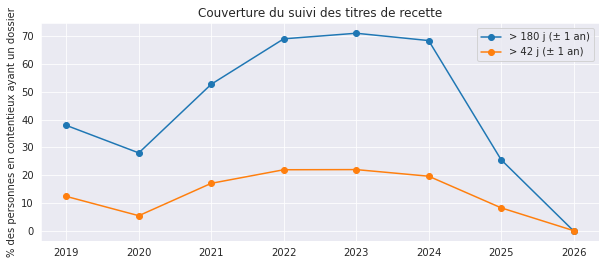

In [40]:
dossiers = k.dropna(subset=['borrowernumber']).groupby('annee_ctx')['borrowernumber'].apply(lambda s: set(s.astype(int)))
lignes = []
for seuil in [SEUIL_CTX, 180]:
    q = observable(prets, seuil)
    q = q[q['retard'] > seuil]
    en_ctx = q.groupby('annee_echeance')['borrowernumber'].apply(lambda s: set(s.astype(int)))
    for annee in range(ANNEE_DEBUT, fraicheur.year + 1):
        c = en_ctx.get(annee, set())
        strict = dossiers.get(annee, set())
        large = set().union(*[dossiers.get(a, set()) for a in (annee - 1, annee, annee + 1)])
        lignes.append({'seuil': f'> {seuil} j', 'année du contentieux': annee, 'personnes en contentieux': len(c),
                       'avec dossier (strict)': len(c & strict), 'couverture stricte %': 100 * len(c & strict) / len(c) if c else np.nan,
                       'avec dossier (± 1 an)': len(c & large), 'couverture ± 1 an %': 100 * len(c & large) / len(c) if c else np.nan})
couverture = pd.DataFrame(lignes).set_index(['seuil', 'année du contentieux'])
display(couverture.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for seuil, g in couverture.reset_index().groupby('seuil'):
    ax.plot(g['année du contentieux'], g['couverture ± 1 an %'], marker='o', label=f'{seuil} (± 1 an)')
ax.set_ylabel('% des personnes en contentieux ayant un dossier')
ax.set_title('Couverture du suivi des titres de recette')
ax.legend()
plt.show()

# 12. Anomalies à traiter

La première ligne correspond aux fiches que vide le script `adm_contentieux_nettoyage_appels.py` (champs d'appel seulement ; il ne touche pas aux champs du titre de recette).

In [41]:
bloc = renseigne(adh['B_address']) | renseigne(adh['B_address2']) | renseigne(adh['B_country']) | renseigne(adh['B_state'])
sans_retard = bloc & ~adh['borrowernumber'].isin(stock['borrowernumber'])
pd.Series({
    "bloc B_ rempli, aucun document en retard > 28 j": int(sans_retard.sum()),
    "  dont aucun prêt en cours": int((sans_retard & ~adh['borrowernumber'].isin(actuels['borrowernumber'])).sum()),
    "dates d'appel au format JJ/MM/AAAA": int(adh['B_address'].astype(str).str.fullmatch(r'\d{2}/\d{2}/\d{4}').sum()),
    "dates B_ illisibles (appel / tiers / titre)": int(adh[['date_appel_illisible', 'date_tiers_illisible', 'date_titre_illisible']].any(axis=1).sum()),
    "résultat d'appel hors valeurs admises": int((renseigne(adh['B_address2']) & adh['resultat_appel'].isna()).sum()),
    "titre 0 avec montant noté ≥ 15 €": int(((adh['etat_titre'] == '0 (< 15 €)') & (adh['montant_note'] >= SEUIL_TITRE_EUR)).sum()),
    "titre numéroté avec montant noté < 15 €": int(((adh['etat_titre'] == 'numéro') & (adh['montant_note'] < SEUIL_TITRE_EUR)).sum()),
    "particuliers du stock, bloc B_ d'un dossier antérieur": int(part['bloc_dossier_anterieur'].sum()),
}, name='fiches').to_frame()

,fiches
"bloc B_ rempli, aucun document en retard > 28 j",1401
dont aucun prêt en cours,1013
dates d'appel au format JJ/MM/AAAA,1173
dates B_ illisibles (appel / tiers / titre),30
résultat d'appel hors valeurs admises,22
titre 0 avec montant noté ≥ 15 €,31
titre numéroté avec montant noté < 15 €,41
"particuliers du stock, bloc B_ d'un dossier antérieur",125


# Limites
- La base de travail est une copie qui n'est pas à jour au jour près : tout est calculé à la date de fraîcheur.
- L'historique commence en juin 2018 ; les prêts sans profil statdb (comptes génériques pour l'essentiel) ne sont pas dans les sections 1 à 4.
- Le « retour douteux » est une hypothèse : il ne sert qu'à borner le plafond.
- Les tests au niveau emprunteur supposent l'indépendance des personnes (pas de prise en compte des foyers / cartes familiales).
- Le bloc `B_` ne garde qu'une information par étape : l'historique des dossiers successifs d'une même personne est perdu, les sections 7 et 8 ne voient que le dernier appel. Le sens de `B_state = 0` (montant < 15 €) est déduit statistiquement, pas documenté.
- La valeur du stock repose sur le prix de remplacement Koha, qui peut différer du montant facturé.
- Les fichiers de suivi des titres sont saisis à la main (formats de date et de référence RAP variables, noms parfois orthographiés différemment de Koha) ; les dossiers non rapprochés concernent surtout des fiches supprimées ou anonymisées. La couverture compte une personne comme couverte si elle a un dossier pour l'année, sans vérifier que tous ses documents y figurent.